Loading CNN model...
Model loaded successfully!


Saving images (2).jpg to images (2).jpg

Top CNN Predictions:
tiger cat - 76.99 %
tabby - 7.08 %
Egyptian cat - 1.39 %
Cardigan - 0.71 %
tiger - 0.59 %


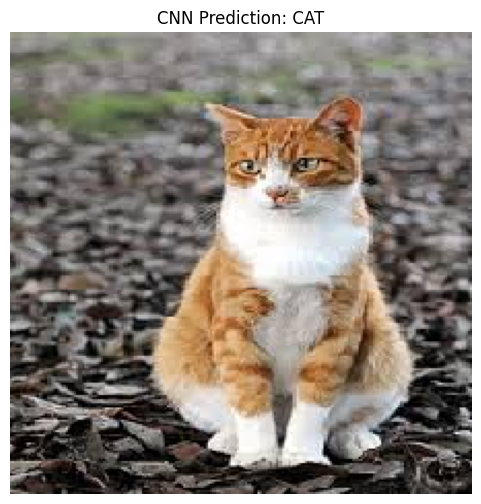


Final CNN Classification: CAT
Top prediction confidence: 76.99 %


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from google.colab import files
from tensorflow.keras.applications.mobilenet_v2 import (
    MobileNetV2, preprocess_input, decode_predictions
)
from tensorflow.keras.preprocessing import image
print("Loading CNN model...")
model = MobileNetV2(weights="imagenet")
print("Model loaded successfully!")
uploaded = files.upload()
image_path = next(iter(uploaded.keys()))
img = image.load_img(image_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = preprocess_input(img_array)
predictions = model.predict(img_array, verbose=0)
results = decode_predictions(predictions, top=5)[0]
print("\nTop CNN Predictions:")
for _, label, score in results:
    print(label.replace("_", " "), "-", round(float(score) * 100, 2), "%")
top_label = results[0][1].lower()
cat_labels = [
    "tabby", "tiger_cat", "persian_cat", "siamese_cat",
    "egyptian_cat", "lynx", "cougar", "snow_leopard",
    "jaguar", "lion", "tiger", "leopard"
]
if "dog" in top_label:
    answer = "DOG"
elif "cat" in top_label or top_label in cat_labels:
    answer = "CAT"
else:
    answer = "NOT CLEARLY A CAT OR DOG"
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.title("CNN Prediction: " + answer)
plt.axis("off")
plt.show()
print("\nFinal CNN Classification:", answer)
print("Top prediction confidence:", round(float(results[0][2]) * 100, 2), "%")
